# Early Warning for Sepsis in the ICU
### A self-learning tutorial: from raw hourly ICU data to an explainable, externally validated sepsis predictor

**Dataset:** PhysioNet/Computing in Cardiology Challenge 2019 — *Early Prediction of Sepsis from Clinical Data*
(40,336 ICU patients from two U.S. hospital systems, open access, no credentialing required).

**Methods:** clinical rule baseline (SIRS) → logistic regression (ML) → gradient-boosted trees with LightGBM (ML)
→ a recurrent neural network (GRU, deep learning) → SHAP explanations → external validation at a second hospital.

---

## What you will learn

By the end of this notebook you will be able to:

1. **Download and assemble** a real, messy, hourly ICU time-series dataset into a single analysis table.
2. **Split data by patient (and by hospital)** so that your evaluation is honest — and explain why a random
   row-level split would leak information.
3. **Engineer causal features** (features that only use the past) from irregularly measured vitals and labs.
4. **Train and compare** a clinical rule, a logistic regression, a LightGBM model, and a GRU.
5. **Evaluate like a clinician would**: not only AUROC, but patient-level sensitivity, false-alarm burden,
   positive predictive value, and *how many hours of warning* the model gives.
6. **Explain** the tree model's predictions with SHAP.
7. **Test transportability** by training at Hospital A and testing at Hospital B.

## How to run this notebook

* **Google Colab (recommended):** *File → Upload notebook*, then *Runtime → Run all*. Every package used here
  (`pandas`, `numpy`, `scikit-learn`, `lightgbm`, `shap`, `torch`, `matplotlib`, `pyarrow`) is pre-installed on Colab.
* **Locally:** `pip install -r requirements.txt`, then `jupyter lab`.
* **Runtime:** ~15–25 minutes end to end on a CPU (most of it is the one-time download of 40k small files).
  Set `FAST_MODE = True` in the configuration cell to use 5,000 patients per hospital for a ~5 minute run.
* No GPU is needed. If one is available the GRU will use it automatically.

## Table of contents

0. Background: what is sepsis and why predict it early?
1. Setup and configuration
2. Download the data
3. Load the data into one table
4. Exploratory data analysis (EDA)
5. Patient-level and hospital-level data splits
6. Feature engineering (causal features only)
7. Baseline: the SIRS clinical rule
8. Model 1: logistic regression
9. Model 2: LightGBM (gradient-boosted trees)
10. Model 3: GRU recurrent neural network
11. Evaluation the way a hospital would use it
12. Explainability with SHAP
13. External validation at Hospital B
14. Takeaways, limitations, and exercises

---
## 0. Background: what is sepsis and why predict it early?

**Sepsis** is a life-threatening organ dysfunction caused by a dysregulated host response to infection
(the *Sepsis-3* definition, Singer et al., JAMA 2016). It is one of the leading causes of death in hospitals,
and every hour of delay in antibiotics is associated with higher mortality. That is why hospitals want
**early warning systems**: software that watches each ICU patient's vitals and labs every hour and raises an
alert *before* sepsis becomes clinically obvious.

### The dataset

The 2019 PhysioNet Challenge (Reyna et al., *Critical Care Medicine* 2020) released hourly data for ICU patients
from **two hospital systems** (we will call them **Hospital A** and **Hospital B**). Each patient is one
pipe-separated file (`p000001.psv`) with **one row per ICU hour** and 41 columns:

| Group | Columns |
|---|---|
| Vital signs (8) | `HR, O2Sat, Temp, SBP, MAP, DBP, Resp, EtCO2` |
| Laboratory values (26) | `BaseExcess, HCO3, FiO2, pH, PaCO2, SaO2, AST, BUN, Alkalinephos, Calcium, Chloride, Creatinine, Bilirubin_direct, Glucose, Lactate, Magnesium, Phosphate, Potassium, Bilirubin_total, TroponinI, Hct, Hgb, PTT, WBC, Fibrinogen, Platelets` |
| Demographics (6) | `Age, Gender, Unit1, Unit2, HospAdmTime, ICULOS` (ICU length of stay in hours = the time index) |
| Outcome (1) | `SepsisLabel` |

### How the label is defined (read this carefully — it shapes everything)

The challenge organizers computed each septic patient's **sepsis onset time** `t_sepsis` from the Sepsis-3
criteria (suspected infection + an acute ≥2-point rise in SOFA score). Then they set:

```
SepsisLabel = 1   for every hour t >= t_sepsis - 6
SepsisLabel = 0   otherwise (and always 0 for patients who never develop sepsis)
```

```
  ICU hour:  1   2   3  ...  t_sepsis-7  t_sepsis-6  ...  t_sepsis  ...  end
  Label:     0   0   0  ...      0           1       ...     1      ...   1
                                             |<-- 6h -->|
                                    "predict 6 hours early" window
```

So the label is **already shifted 6 hours into the future**. A model that outputs a high score at an hour
where `SepsisLabel = 1` is, by construction, predicting sepsis up to 6 hours before the clinical onset.
We therefore frame the task as **hour-by-hour binary classification**: *"Given everything observed about this
patient up to and including this hour, will they meet sepsis criteria within the next ~6 hours?"*

> **Key constraint — causality.** At hour *t* a real system only knows hours 1…*t*. Every feature we build must
> use only past and present values, never future ones. Violating this produces beautiful but useless models.

---
## 1. Setup and configuration

All tunable settings live in one cell so that anyone re-running the tutorial can change them in one place.
We also fix random seeds so results are reproducible.

In [1]:
# ---- Standard library -------------------------------------------------------
import os                      # file paths / environment
import re                      # regex, used to parse the PhysioNet file listing
import time                    # simple timing + retry back-off
import random                  # Python's RNG (seeded below for reproducibility)
import urllib.parse            # URL-encode the S3 listing token
import urllib.request          # download files without extra dependencies
import warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

# ---- Scientific Python -------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- Machine learning ---------------------------------------------------------
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve)
from sklearn.calibration import calibration_curve
import lightgbm as lgb
import shap

# ---- Deep learning ------------------------------------------------------------
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)   # library deprecation notices, not errors
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# ============================ CONFIGURATION ====================================
DATA_DIR = Path("data")                    # where raw files + cached tables are stored
SETS = {"A": "training_setA",              # Hospital A -> development (train/val/test)
        "B": "training_setB"}              # Hospital B -> external validation only
FAST_MODE = False                          # True = 5,000 patients per hospital (quick demo run)
MAX_PATIENTS = 5000 if FAST_MODE else None
N_DOWNLOAD_THREADS = 32                    # parallel downloads (files are tiny, ~5 KB each)
SEED = 42                                  # one seed to rule them all
TARGET_SENSITIVITY = 0.80                  # alert threshold is chosen to catch 80% of septic patients
# ===============================================================================

# Make every source of randomness deterministic.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"pandas {pd.__version__} | scikit-learn {__import__('sklearn').__version__} | "
      f"lightgbm {lgb.__version__} | torch {torch.__version__} | device: {DEVICE}")

# ---- A consistent, colorblind-checked plotting style ---------------------------
# Each model keeps the same color in every figure so readers can follow it across the notebook.
COLORS = {"SIRS rule": "#898781",            # muted gray: the non-ML reference
          "Logistic regression": "#2a78d6",  # blue
          "LightGBM": "#eb6834",             # orange
          "GRU": "#1baf7a"}                  # aqua
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "text.color": "#0b0b0b",
    "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "legend.frameon": False,
})

pandas 3.0.6 | scikit-learn 1.9.1 | lightgbm 4.7.0 | torch 2.6.0+cpu | device: cpu


---
## 2. Download the data

PhysioNet does not offer a single zip for this dataset; instead each patient is one small file. PhysioNet mirrors
its open datasets on Amazon S3 (`physionet-open`), which is fast and allows many parallel requests.

**Strategy**
1. List the bucket to get the exact patient file names.
2. Download each file from the S3 mirror using a thread pool (I/O-bound work → threads are ideal).
3. Skip files that already exist, so re-running the cell is cheap and an interrupted download can resume.

In [2]:
# "dualstack" endpoint = reachable over both IPv4 and IPv6.
S3_BUCKET = "https://physionet-open.s3.dualstack.us-east-1.amazonaws.com"
PREFIX = "challenge-2019/1.0.0/training/{set_name}/"
S3_URL = S3_BUCKET + "/" + PREFIX + "{fname}"


def list_patient_files(set_name: str) -> list[str]:
    """Return the sorted list of patient file names (e.g. 'p000001.psv') in one training set.

    Uses the S3 'ListObjectsV2' API, which returns at most 1,000 names per page, so we follow
    the continuation token until the listing is complete.
    """
    names, token = [], None
    while True:
        url = f"{S3_BUCKET}/?list-type=2&prefix={PREFIX.format(set_name=set_name)}"
        if token:
            url += "&continuation-token=" + urllib.parse.quote(token)
        with urllib.request.urlopen(url, timeout=120) as resp:
            xml = resp.read().decode("utf-8")
        names += re.findall(r"(p\d{6}\.psv)</Key>", xml)       # every patient file: p + 6 digits + .psv
        token_match = re.search(r"<NextContinuationToken>(.*?)</NextContinuationToken>", xml)
        if not token_match:
            return sorted(set(names))
        token = token_match.group(1)


def download_one(set_name: str, fname: str, out_dir: Path, retries: int = 4) -> None:
    """Download a single patient file, retrying on transient network errors."""
    dest = out_dir / fname
    if dest.exists() and dest.stat().st_size > 0:      # already downloaded -> nothing to do
        return
    url = S3_URL.format(set_name=set_name, fname=fname)
    for attempt in range(retries):
        try:
            with urllib.request.urlopen(url, timeout=60) as resp:
                content = resp.read()
            tmp = dest.with_suffix(".tmp")               # write to a temp file, then rename,
            tmp.write_bytes(content)                     # so a crash never leaves a half-written .psv
            tmp.replace(dest)
            return
        except Exception:
            time.sleep(2 ** attempt)                     # exponential back-off: 1s, 2s, 4s, ...
    raise RuntimeError(f"Failed to download {url}")


def download_set(set_name: str, max_patients=None) -> Path:
    out_dir = DATA_DIR / set_name
    out_dir.mkdir(parents=True, exist_ok=True)
    files = list_patient_files(set_name)
    if max_patients:
        files = files[:max_patients]
    todo = [f for f in files if not (out_dir / f).exists()]
    print(f"{set_name}: {len(files):,} patient files listed, {len(todo):,} still to download")
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=N_DOWNLOAD_THREADS) as pool:
        futures = [pool.submit(download_one, set_name, f, out_dir) for f in todo]
        for i, fut in enumerate(as_completed(futures), 1):
            fut.result()                                 # re-raises any download error
            if i % 5000 == 0:
                print(f"   {i:,}/{len(todo):,} files ({time.time() - t0:.0f}s)")
    print(f"   done in {time.time() - t0:.0f}s")
    return out_dir


for hospital, set_name in SETS.items():
    download_set(set_name, MAX_PATIENTS)

training_setA: 20,336 patient files listed, 0 still to download
   done in 0s


training_setB: 20,000 patient files listed, 0 still to download
   done in 0s


---
## 3. Load the data into one table

We read every `.psv` file, tag each row with its `patient_id` and `hospital`, and stack everything into one long
("tidy") DataFrame: **one row = one patient-hour**. Reading 40k files takes a couple of minutes, so we cache the
combined table as a Parquet file — the second run of this cell takes about one second.

In [3]:
def read_patient(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, sep="|")                 # PhysioNet uses '|' as the separator
    df.insert(0, "patient_id", path.stem)           # 'p000001'
    return df


def load_set(hospital: str, set_name: str, max_patients=None) -> pd.DataFrame:
    suffix = "_fast" if max_patients else ""
    cache = DATA_DIR / f"{set_name}{suffix}.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    files = sorted((DATA_DIR / set_name).glob("p*.psv"))[:max_patients]
    with ThreadPoolExecutor(max_workers=8) as pool:  # parsing is partly I/O-bound, so threads help
        frames = list(pool.map(read_patient, files))
    df = pd.concat(frames, ignore_index=True)
    df.insert(1, "hospital", hospital)
    df.to_parquet(cache, index=False)
    return df


t0 = time.time()
raw = pd.concat([load_set(h, s, MAX_PATIENTS) for h, s in SETS.items()], ignore_index=True)
# Patient IDs are unique across the two sets (set B ids start at p100001), but we make that explicit:
assert raw.groupby("patient_id")["hospital"].nunique().max() == 1
raw = raw.sort_values(["patient_id", "ICULOS"]).reset_index(drop=True)
print(f"Loaded {len(raw):,} patient-hours from {raw.patient_id.nunique():,} patients in {time.time() - t0:.0f}s")
raw.head()

Loaded 1,552,210 patient-hours from 40,336 patients in 1s


,patient_id,hospital,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,FiO2,pH,PaCO2,SaO2,AST,BUN,Alkalinephos,Calcium,Chloride,Creatinine,Bilirubin_direct,Glucose,Lactate,Magnesium,Phosphate,Potassium,Bilirubin_total,TroponinI,Hct,Hgb,PTT,WBC,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel
0,p000001,A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,83.14,0,NaN,NaN,-0.03,1,0
1,p000001,A,97.0,95.0,NaN,98.0,75.33,NaN,19.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,83.14,0,NaN,NaN,-0.03,2,0
2,p000001,A,89.0,99.0,NaN,122.0,86.00,NaN,22.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,83.14,0,NaN,NaN,-0.03,3,0
3,p000001,A,90.0,95.0,NaN,NaN,NaN,NaN,30.0,NaN,24.0,NaN,NaN,7.36,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,83.14,0,NaN,NaN,-0.03,4,0
4,p000001,A,103.0,88.5,NaN,122.0,91.33,NaN,24.5,NaN,NaN,NaN,0.28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,83.14,0,NaN,NaN,-0.03,5,0


Notice how many `NaN`s there are. **Missing does not mean "error" here** — it means "not measured this hour."
Heart rate is charted nearly every hour, but a lactate might be drawn once a day, and *only* if a clinician is
worried. Handling this sparsity well is the central engineering problem of this tutorial.

Let's name the column groups once so the rest of the code can refer to them.

In [4]:
VITALS = ["HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp", "EtCO2"]
LABS = ["BaseExcess", "HCO3", "FiO2", "pH", "PaCO2", "SaO2", "AST", "BUN", "Alkalinephos", "Calcium",
        "Chloride", "Creatinine", "Bilirubin_direct", "Glucose", "Lactate", "Magnesium", "Phosphate",
        "Potassium", "Bilirubin_total", "TroponinI", "Hct", "Hgb", "PTT", "WBC", "Fibrinogen", "Platelets"]
DEMOGRAPHICS = ["Age", "Gender", "HospAdmTime", "ICULOS"]
# Unit1/Unit2 (MICU vs SICU) are missing for ~40% of patients and are coded differently per hospital,
# so we leave them out to keep the model transportable.
MEASUREMENTS = VITALS + LABS

---
## 4. Exploratory data analysis (EDA)

Before modeling, we want answers to four questions:

1. How many patients develop sepsis (class balance), and does it differ by hospital?
2. How long are ICU stays, and *when* does sepsis start?
3. How sparse is each variable?
4. What does a single septic patient look like over time?

We start by collapsing the hourly table to **one row per patient**.

In [5]:
# First hour where SepsisLabel == 1 (NaN for patients who never become septic)
first_pos = raw.loc[raw.SepsisLabel == 1].groupby("patient_id")["ICULOS"].min()

patients = raw.groupby("patient_id").agg(
    hospital=("hospital", "first"),
    n_hours=("ICULOS", "size"),
    age=("Age", "first"),
    male=("Gender", "first"),
    septic=("SepsisLabel", "max"),
)
patients["first_label_hour"] = first_pos
# Because the label is shifted 6 h early, the clinical onset is 6 h after the first positive label.
patients["t_sepsis"] = patients["first_label_hour"] + 6

summary = patients.groupby("hospital").agg(
    patients=("septic", "size"),
    septic_patients=("septic", "sum"),
    pct_septic=("septic", "mean"),
    median_icu_hours=("n_hours", "median"),
    median_age=("age", "median"),
)
summary["pct_septic"] = (100 * summary.pct_septic).round(1)
hourly_pos = raw.groupby("hospital")["SepsisLabel"].mean().mul(100).round(2)
summary["pct_positive_hours"] = hourly_pos
summary

,patients,septic_patients,pct_septic,median_icu_hours,median_age,pct_positive_hours
hospital,,,,,,
A,20336,1790,8.8,39.0,64.67,2.17
B,20000,1142,5.7,38.0,62.00,1.41


**Reading the table:** only 6–9% of patients (and ~2% of patient-hours) are positive. This **class imbalance**
means *accuracy is a useless metric* — predicting "no sepsis" for everyone is ~98% accurate per hour. We will use
AUROC, **AUPRC** (area under the precision–recall curve, which is sensitive to imbalance), and patient-level alert
metrics instead. Note also that the two hospitals differ in prevalence and in patient mix — a hint of the
distribution shift we will face in Section 13.

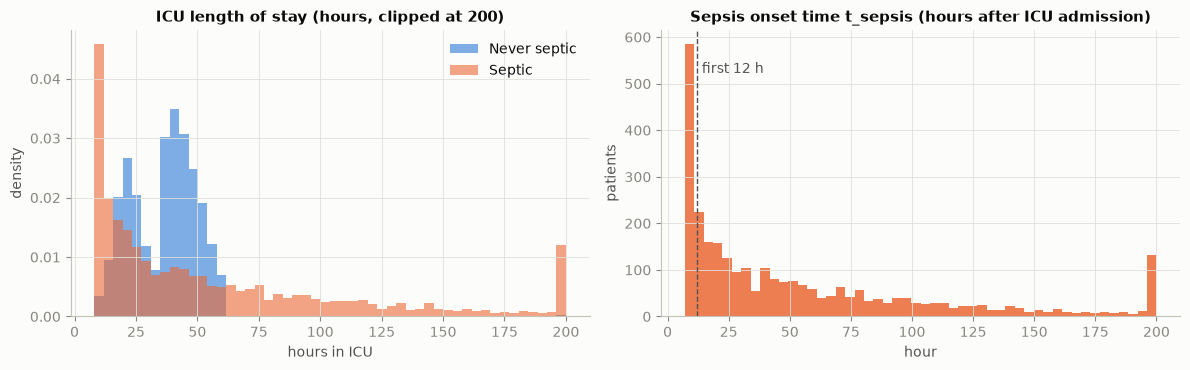

Septic patients whose onset is within the first 12 ICU hours: 24%


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

# (a) ICU length of stay, septic vs non-septic
for label, color, name in [(0, "#2a78d6", "Never septic"), (1, "#eb6834", "Septic")]:
    axes[0].hist(patients.loc[patients.septic == label, "n_hours"].clip(upper=200), bins=50,
                 density=True, alpha=0.6, color=color, label=name)
axes[0].set(title="ICU length of stay (hours, clipped at 200)", xlabel="hours in ICU", ylabel="density")
axes[0].legend()

# (b) When does sepsis start?
axes[1].hist(patients.t_sepsis.dropna().clip(upper=200), bins=50, color="#eb6834", alpha=0.85)
axes[1].axvline(12, color="#52514e", ls="--", lw=1)
axes[1].text(14, axes[1].get_ylim()[1] * 0.85, "first 12 h", color="#52514e")
axes[1].set(title="Sepsis onset time t_sepsis (hours after ICU admission)", xlabel="hour", ylabel="patients")
plt.tight_layout()
plt.show()

print(f"Septic patients whose onset is within the first 12 ICU hours: "
      f"{(patients.t_sepsis <= 12).sum() / patients.septic.sum():.0%}")

Two things to notice: septic patients stay much longer (partly a *consequence* of sepsis), and a sizeable fraction
of patients are labeled septic almost immediately after ICU admission — they likely arrived already septic, which
is not something an ICU early-warning system can "predict early." We keep them (the challenge did too) but keep it
in mind when interpreting lead times.

### How sparse is each variable?

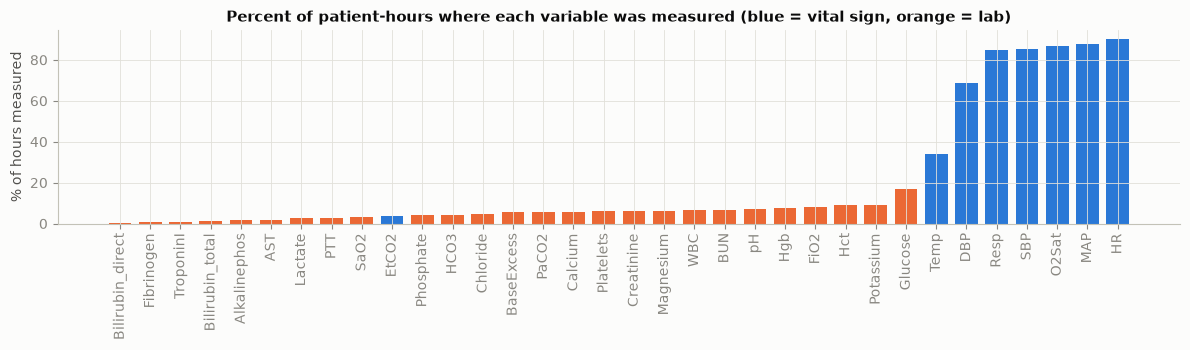

In [7]:
missing = raw[MEASUREMENTS].notna().mean().sort_values() * 100
fig, ax = plt.subplots(figsize=(12, 3.6))
bar_colors = ["#2a78d6" if c in VITALS else "#eb6834" for c in missing.index]
ax.bar(missing.index, missing.values, color=bar_colors, width=0.75)
ax.set(title="Percent of patient-hours where each variable was measured (blue = vital sign, orange = lab)",
       ylabel="% of hours measured")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

Vital signs are recorded most hours (except `EtCO2`, only for ventilated patients); most labs are measured in fewer
than 10% of hours. Two consequences for feature engineering:

* We will **carry the last observed value forward** (what a clinician does mentally: "the last lactate was 3.1").
* We will add **"hours since last measured"** features. *When* a lab was ordered is itself information — clinicians
  order lactates when they suspect sepsis. (This is powerful, but also a form of *clinician-behavior leakage*; we
  discuss it in Section 14.)

### One septic patient, hour by hour

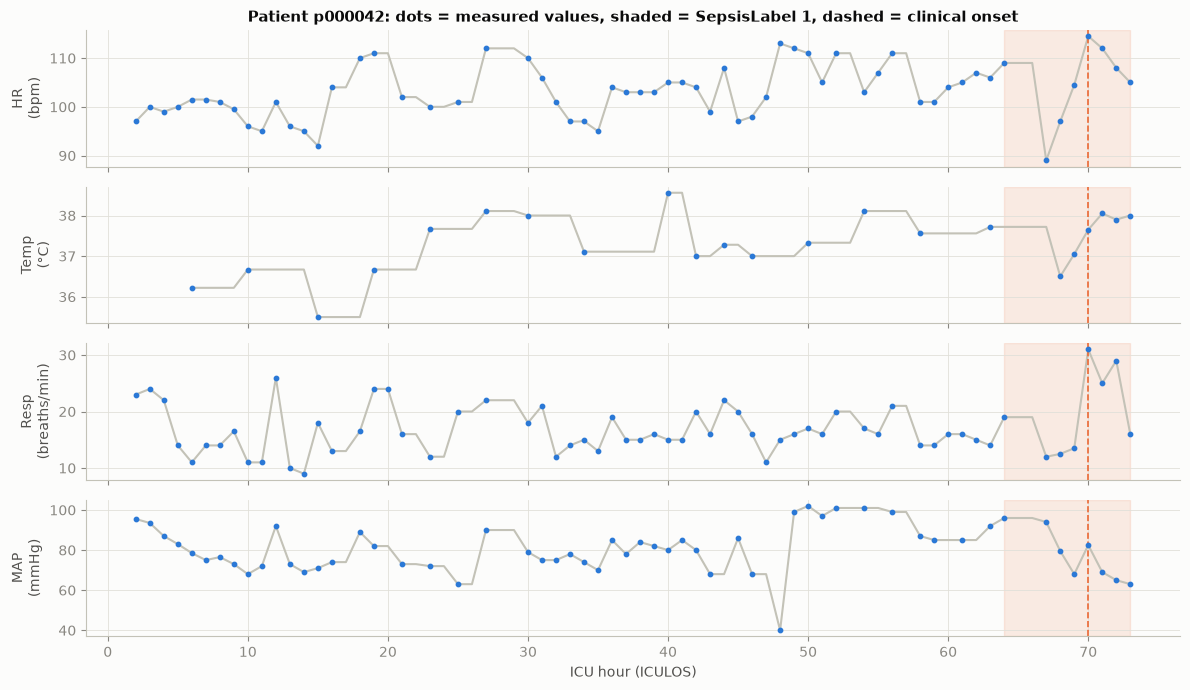

In [8]:
# Pick a septic patient from Hospital A with a reasonably long stay and an onset after the first day.
example_id = patients.query("hospital == 'A' and septic == 1 and t_sepsis > 30 and 60 < n_hours < 120").index[0]
ex = raw.loc[raw.patient_id == example_id]

fig, axes = plt.subplots(4, 1, figsize=(12, 7), sharex=True)
for ax, var, unit in zip(axes, ["HR", "Temp", "Resp", "MAP"], ["bpm", "°C", "breaths/min", "mmHg"]):
    ax.plot(ex.ICULOS, ex[var].ffill(), color="#c3c2b7", lw=1.5)          # carried-forward line
    ax.scatter(ex.ICULOS, ex[var], s=10, color="#2a78d6", zorder=3)       # actual measurements
    ax.axvspan(patients.loc[example_id, "first_label_hour"], ex.ICULOS.max(), color="#eb6834", alpha=0.12)
    ax.axvline(patients.loc[example_id, "t_sepsis"], color="#eb6834", ls="--", lw=1.2)
    ax.set_ylabel(f"{var}\n({unit})")
axes[0].set_title(f"Patient {example_id}: dots = measured values, shaded = SepsisLabel 1, dashed = clinical onset")
axes[-1].set_xlabel("ICU hour (ICULOS)")
plt.tight_layout()
plt.show()

---
## 5. Patient-level and hospital-level data splits

This is the single most common mistake in clinical ML tutorials, so it gets its own section.

**Wrong:** shuffle the 1.5 million rows and split 80/20. Hour 10 of patient X lands in training and hour 11 of the
*same patient* lands in the test set. The model can simply recognize the patient, and the test score is inflated.

**Right:** split **patients**, so every hour of a given patient is in exactly one set. We go one step further:

| Split | Source | Purpose |
|---|---|---|
| Train (70%) | Hospital A patients | fit model parameters |
| Validation (15%) | Hospital A patients | early stopping, choose the alert threshold |
| Internal test (15%) | Hospital A patients | unbiased estimate *at the same hospital* |
| **External test** | **all Hospital B patients** | does the model transport to a different hospital? |

We **stratify** by `septic` so each split has the same proportion of septic patients.

In [9]:
dev_patients = patients.query("hospital == 'A'")
train_ids, holdout_ids = train_test_split(dev_patients.index.to_numpy(), test_size=0.30,
                                          stratify=dev_patients.septic, random_state=SEED)
val_ids, test_ids = train_test_split(holdout_ids, test_size=0.50,
                                     stratify=dev_patients.loc[holdout_ids, "septic"], random_state=SEED)
ext_ids = patients.query("hospital == 'B'").index

split_of = pd.Series("ext", index=patients.index)
split_of[train_ids], split_of[val_ids], split_of[test_ids] = "train", "val", "test"
patients["split"] = split_of

# Sanity checks: no patient appears in two splits.
assert len(set(train_ids) & set(val_ids)) == len(set(train_ids) & set(test_ids)) == len(set(val_ids) & set(test_ids)) == 0
patients.groupby("split").agg(patients=("septic", "size"), pct_septic=("septic", "mean")).round(3)

,patients,pct_septic
split,,
ext,20000,0.057
test,3051,0.088
train,14235,0.088
val,3050,0.088


---
## 6. Feature engineering (causal features only)

For every patient-hour we build features that a bedside system could compute *at that hour*:

| Feature family | Example | Why |
|---|---|---|
| Last observed value | `Lactate_last` | forward-fill within the patient; never across patients |
| Hours since last measured | `Lactate_hrs_since` | measurement frequency carries signal; capped at 72 h, "never measured" = 72 |
| 6-hour rolling statistics (vitals) | `HR_mean6`, `HR_min6`, `HR_max6`, `HR_std6` | trends and variability, not just snapshots |
| 6-hour change (vitals) | `Resp_delta6` | is the patient getting worse? |
| Clinical ratios | `shock_index = HR / SBP`, `BUN / creatinine` | domain knowledge clinicians already use |
| Demographics / time | `Age`, `Gender`, `HospAdmTime`, `ICULOS` | baseline risk and time in ICU |

Every operation below is done **within** `groupby("patient_id")`, and only looks backwards
(`ffill`, `rolling` over the current and previous rows, `shift(+6)`). We never use `bfill` or centered windows.

In [10]:
ROLL_VITALS = ["HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp"]   # EtCO2 is too sparse to roll
STALE_CAP = 72.0                                                       # hours


def make_features(df: pd.DataFrame) -> pd.DataFrame:
    """Turn the raw hourly table into a causal feature table (same rows, same order)."""
    df = df.sort_values(["patient_id", "ICULOS"]).reset_index(drop=True)
    pid = df["patient_id"]
    feats = {}

    # 1) Last observation carried forward (LOCF), within each patient only.
    last = df[MEASUREMENTS].groupby(pid).ffill()
    for c in MEASUREMENTS:
        feats[f"{c}_last"] = last[c]

    # 2) Hours since the variable was last measured (capped; never measured -> cap).
    for c in MEASUREMENTS:
        t_measured = df["ICULOS"].where(df[c].notna())          # ICU hour of each real measurement
        t_last = t_measured.groupby(pid).ffill()                 # most recent measurement hour so far
        feats[f"{c}_hrs_since"] = (df["ICULOS"] - t_last).clip(upper=STALE_CAP).fillna(STALE_CAP)

    # 3) Rolling 6-hour window statistics on (forward-filled) vitals.
    #    rolling(6) at row t uses rows t-5 ... t  -> only the past, so it is causal.
    rolled = last[ROLL_VITALS].groupby(pid).rolling(6, min_periods=1)
    for stat in ["mean", "min", "max", "std"]:
        r = getattr(rolled, stat)().reset_index(level=0, drop=True).sort_index()
        for c in ROLL_VITALS:
            feats[f"{c}_{stat}6"] = r[c]

    # 4) Change over the last 6 hours (positive = rising).
    lag6 = last[ROLL_VITALS].groupby(pid).shift(6)
    for c in ROLL_VITALS:
        feats[f"{c}_delta6"] = last[c] - lag6[c]

    # 5) Clinically motivated ratios.
    feats["shock_index"] = last["HR"] / last["SBP"]
    feats["bun_creatinine_ratio"] = last["BUN"] / last["Creatinine"]

    # 6) Demographics and time.
    for c in DEMOGRAPHICS:
        feats[c] = df[c]

    X = pd.DataFrame(feats).astype("float32").replace([np.inf, -np.inf], np.nan)
    meta = df[["patient_id", "hospital", "ICULOS", "SepsisLabel"]].copy()
    meta["split"] = meta["patient_id"].map(patients["split"])
    return pd.concat([meta, X.add_prefix("f_")], axis=1)


t0 = time.time()
table = make_features(raw)
FEATURES = [c for c in table.columns if c.startswith("f_")]
print(f"Feature table: {table.shape[0]:,} rows x {len(FEATURES)} features  ({time.time() - t0:.0f}s)")
table[["patient_id", "ICULOS", "SepsisLabel", "f_HR_last", "f_HR_mean6", "f_HR_delta6",
       "f_Lactate_last", "f_Lactate_hrs_since", "f_shock_index"]].iloc[20:28]

Feature table: 1,552,210 rows x 109 features  (37s)


,patient_id,ICULOS,SepsisLabel,f_HR_last,f_HR_mean6,f_HR_delta6,f_Lactate_last,f_Lactate_hrs_since,f_shock_index
20,p000001,21,0,113.0,107.000000,7.0,NaN,72.0,0.768707
21,p000001,22,0,98.0,105.166664,-11.0,NaN,72.0,0.731343
22,p000001,23,0,100.0,104.666664,-3.0,NaN,72.0,0.746269
23,p000001,24,0,102.0,104.333336,-2.0,NaN,72.0,0.772727
24,p000001,25,0,108.0,105.000000,4.0,NaN,72.0,0.724832
25,p000001,26,0,107.0,104.666664,-2.0,NaN,72.0,0.685897
26,p000001,27,0,104.0,103.166664,-9.0,NaN,72.0,0.619048
27,p000001,28,0,102.0,103.833336,4.0,NaN,72.0,0.698630


A quick **leakage unit test**: if our features are truly causal, then computing features on a patient's record
*truncated at hour t* must give exactly the same row-t features as computing them on the full record.
This is a cheap test that catches `bfill`, centered windows, and negative shifts.

In [11]:
full = table.loc[table.patient_id == example_id, FEATURES].reset_index(drop=True)
cut_at = 30
truncated = make_features(raw.loc[(raw.patient_id == example_id) & (raw.ICULOS <= cut_at)])
pd.testing.assert_frame_equal(full.iloc[:len(truncated)], truncated[FEATURES].reset_index(drop=True))
print(f"Causality check passed: features up to hour {cut_at} do not depend on the future.")

Causality check passed: features up to hour 30 do not depend on the future.


Now split the feature table into the four sets defined in Section 5.

In [12]:
parts = {s: table.loc[table.split == s].reset_index(drop=True) for s in ["train", "val", "test", "ext"]}
X = {s: d[FEATURES] for s, d in parts.items()}
y = {s: d["SepsisLabel"].to_numpy() for s, d in parts.items()}
for s, d in parts.items():
    print(f"{s:>5}: {len(d):>9,} hours | {d.patient_id.nunique():>6,} patients | {y[s].mean():.2%} positive hours")

train:   552,665 hours | 14,235 patients | 2.17% positive hours
  val:   118,499 hours |  3,050 patients | 2.16% positive hours
 test:   119,051 hours |  3,051 patients | 2.16% positive hours
  ext:   761,995 hours | 20,000 patients | 1.41% positive hours


---
## 7. Baseline: the SIRS clinical rule

Before any ML, ask: *what would a simple bedside rule achieve?* The **SIRS** criteria (Systemic Inflammatory
Response Syndrome) have been used to screen for sepsis for decades. One point each for:

* Temperature > 38 °C or < 36 °C
* Heart rate > 90 bpm
* Respiratory rate > 20 /min (or PaCO₂ < 32 mmHg)
* White blood cell count > 12 or < 4 (×10⁹/L)

The score (0–4) can be used directly as a risk score. Any ML model that cannot beat this is not worth deploying.

In [13]:
def sirs_score(d: pd.DataFrame) -> np.ndarray:
    temp, hr, resp = d["f_Temp_last"], d["f_HR_last"], d["f_Resp_last"]
    paco2, wbc = d["f_PaCO2_last"], d["f_WBC_last"]
    score = ((temp > 38) | (temp < 36)).astype(int) \
          + (hr > 90).astype(int) \
          + ((resp > 20) | (paco2 < 32)).astype(int) \
          + ((wbc > 12) | (wbc < 4)).astype(int)        # comparisons with NaN are False -> 0 points
    return score.to_numpy(dtype=float)


preds = {s: {} for s in parts}     # preds[split][model_name] = hourly risk scores
for s in parts:
    preds[s]["SIRS rule"] = sirs_score(parts[s])
print(f"SIRS rule, internal test: AUROC {roc_auc_score(y['test'], preds['test']['SIRS rule']):.3f}, "
      f"AUPRC {average_precision_score(y['test'], preds['test']['SIRS rule']):.3f} "
      f"(a random model's AUPRC = prevalence = {y['test'].mean():.3f})")

SIRS rule, internal test: AUROC 0.628, AUPRC 0.032 (a random model's AUPRC = prevalence = 0.022)


---
## 8. Model 1: logistic regression

Logistic regression is the classic, interpretable clinical model. It needs complete, scaled inputs, so we wrap it
in a scikit-learn **Pipeline**:

1. `SimpleImputer(median)` fills values that were never measured (e.g. a patient with no lactate yet).
   The medians are learned **from the training set only** — the pipeline guarantees this.
2. `StandardScaler` puts features on comparable scales so the regularization penalty treats them fairly.
3. `LogisticRegression` with L2 regularization.

We do *not* re-weight classes: the model then outputs (approximately) calibrated probabilities, and we handle the
imbalance later by choosing the alert threshold.

In [14]:
t0 = time.time()
logreg = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(C=0.1, max_iter=2000),
)
logreg.fit(X["train"], y["train"])
for s in parts:
    preds[s]["Logistic regression"] = logreg.predict_proba(X[s])[:, 1]
print(f"Trained in {time.time() - t0:.0f}s | val AUROC "
      f"{roc_auc_score(y['val'], preds['val']['Logistic regression']):.3f}, "
      f"val AUPRC {average_precision_score(y['val'], preds['val']['Logistic regression']):.3f}")

Trained in 12s | val AUROC 0.782, val AUPRC 0.090


---
## 9. Model 2: LightGBM (gradient-boosted decision trees)

Gradient boosting builds hundreds of small decision trees, each correcting the errors of the previous ones.
It is usually the strongest model family for tabular clinical data, and was used by most top teams in the
2019 Challenge. Practical advantages here:

* **Handles missing values natively** — at each split it learns which side `NaN` should go to, so no imputation.
* Captures **non-linear effects and interactions** (e.g. tachycardia matters more when blood pressure is low).
* Is fast on 500k+ rows.

We use the validation set for **early stopping**: keep adding trees until validation AUPRC hasn't improved for
100 rounds, then roll back to the best iteration. This picks the model size without touching the test sets.

In [15]:
t0 = time.time()
gbm = lgb.LGBMClassifier(
    n_estimators=3000,          # an upper bound; early stopping picks the real number
    learning_rate=0.03,
    num_leaves=63,              # tree complexity
    min_child_samples=200,      # each leaf must cover >=200 patient-hours (regularization)
    subsample=0.8, subsample_freq=1,   # row bagging
    colsample_bytree=0.6,       # feature bagging
    reg_lambda=1.0,
    random_state=SEED, n_jobs=-1, verbose=-1,
)
gbm.fit(X["train"], y["train"],
        eval_set=[(X["val"], y["val"])], eval_metric="average_precision",
        callbacks=[lgb.early_stopping(100, verbose=False)])
for s in parts:
    preds[s]["LightGBM"] = gbm.predict_proba(X[s])[:, 1]
print(f"Trained in {time.time() - t0:.0f}s | best iteration {gbm.best_iteration_} | val AUROC "
      f"{roc_auc_score(y['val'], preds['val']['LightGBM']):.3f}, "
      f"val AUPRC {average_precision_score(y['val'], preds['val']['LightGBM']):.3f}")

Trained in 16s | best iteration 164 | val AUROC 0.820, val AUPRC 0.123


---
## 10. Model 3: GRU recurrent neural network (deep learning)

The tabular models only "see" the past through features *we* designed (last value, 6-hour windows...). A
**recurrent neural network** instead reads the patient's whole history one hour at a time and learns its own
summary of the past in a hidden state vector:

```
 hour 1      hour 2      hour 3            hour t
  x1 ──▶[GRU]──▶[GRU]──▶[GRU]── ... ──▶[GRU]──▶ h_t ──▶ Linear ──▶ P(sepsis label at hour t)
          h1      h2      h3
```

A **GRU** (Gated Recurrent Unit) is a lighter cousin of the LSTM. Because it is **unidirectional**, the prediction at
hour *t* depends only on hours 1…*t* — the model is causal by construction. (A *bidirectional* RNN would peek at
the future and must never be used for real-time prediction.)

**Inputs per hour (72 numbers):**
* the 34 forward-filled measurements, standardized with training-set mean/std; still-missing values set to 0 (= the mean)
* the 4 demographic/time columns `Age`, `Gender`, `HospAdmTime`, `ICULOS`, standardized the same way
* 34 binary **mask** values: 1 if the variable was actually measured this hour (lets the network learn from *when*
  things are measured, the same idea as `hrs_since`)

We deliberately give the GRU only these raw signals — none of the hand-made rolling/trend features — so it has to
learn its own summary of the past.

**Training details:** patients have different lengths, so we **pad** sequences in a batch to the same length,
use `pack_padded_sequence` so the GRU skips the padding, and **mask** padded steps out of the loss.

In [16]:
VALUE_INPUTS = [f"f_{c}_last" for c in MEASUREMENTS] + [f"f_{c}" for c in DEMOGRAPHICS]

# Standardization statistics from the TRAINING split only (never from val/test -> no leakage).
mu = X["train"][VALUE_INPUTS].mean()
sd = X["train"][VALUE_INPUTS].std().replace(0, 1)


def to_sequences(d: pd.DataFrame):
    """Convert one split's hourly rows into a list of per-patient tensors (inputs, labels)."""
    vals = ((d[VALUE_INPUTS] - mu) / sd).fillna(0.0)                       # standardized values, missing -> 0
    measured = (d[[f"f_{c}_hrs_since" for c in MEASUREMENTS]] == 0)     # 1 if measured this very hour
    inputs = np.hstack([vals.to_numpy(np.float32), measured.to_numpy(np.float32)])
    labels = d["SepsisLabel"].to_numpy(np.float32)
    # Rows are sorted by patient then hour, so each patient is a contiguous block.
    boundaries = np.flatnonzero(d["patient_id"].to_numpy()[1:] != d["patient_id"].to_numpy()[:-1]) + 1
    xs = [torch.from_numpy(a) for a in np.split(inputs, boundaries)]
    ys = [torch.from_numpy(a) for a in np.split(labels, boundaries)]
    return xs, ys


seqs = {s: to_sequences(parts[s]) for s in parts}
N_INPUTS = seqs["train"][0][0].shape[1]
print(f"{len(seqs['train'][0]):,} training sequences, {N_INPUTS} inputs per hour")

14,235 training sequences, 72 inputs per hour


In [17]:
class SepsisGRU(nn.Module):
    def __init__(self, n_inputs: int, hidden: int = 64, layers: int = 2, dropout: float = 0.2):
        super().__init__()
        self.input_proj = nn.Sequential(nn.Linear(n_inputs, hidden), nn.ReLU())  # mix raw inputs first
        self.gru = nn.GRU(hidden, hidden, num_layers=layers, batch_first=True, dropout=dropout)
        self.head = nn.Linear(hidden, 1)                                          # one logit per hour

    def forward(self, x, lengths):
        z = self.input_proj(x)
        packed = pack_padded_sequence(z, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.gru(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.shape[1])
        return self.head(out).squeeze(-1)                                         # [batch, time]


def batches(xs, ys, batch_size, shuffle):
    order = np.random.permutation(len(xs)) if shuffle else np.arange(len(xs))
    for i in range(0, len(xs), batch_size):
        idx = order[i:i + batch_size]
        lengths = torch.tensor([len(xs[j]) for j in idx])
        xb = pad_sequence([xs[j] for j in idx], batch_first=True)               # zero-pad to longest
        yb = pad_sequence([ys[j] for j in idx], batch_first=True)
        mask = torch.arange(xb.shape[1])[None, :] < lengths[:, None]           # True = real hour
        yield xb.to(DEVICE), yb.to(DEVICE), mask.to(DEVICE), lengths


@torch.no_grad()
def gru_predict(model, xs, ys):
    """Return hourly probabilities in the same row order as the split's DataFrame."""
    model.eval()
    out = []
    for xb, _, mask, lengths in batches(xs, ys, 512, shuffle=False):
        prob = torch.sigmoid(model(xb, lengths))
        out.append(prob[mask].cpu().numpy())        # boolean mask flattens row-major = patient, then hour
    return np.concatenate(out)


torch.manual_seed(SEED)
np.random.seed(SEED)
gru = SepsisGRU(N_INPUTS).to(DEVICE)
optimizer = torch.optim.Adam(gru.parameters(), lr=1e-3, weight_decay=1e-5)
loss_fn = nn.BCEWithLogitsLoss(reduction="none")   # per-hour loss so we can mask padding

best_auprc, best_state, patience, history = -1.0, None, 0, []
t0 = time.time()
for epoch in range(1, 31):
    gru.train()
    running = []
    for xb, yb, mask, lengths in batches(*seqs["train"], batch_size=64, shuffle=True):
        logits = gru(xb, lengths)
        loss = (loss_fn(logits, yb) * mask).sum() / mask.sum()   # average over real hours only
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(gru.parameters(), 1.0)          # keeps RNN training stable
        optimizer.step()
        running.append(loss.item())
    val_auprc = average_precision_score(y["val"], gru_predict(gru, *seqs["val"]))
    history.append((epoch, np.mean(running), val_auprc))
    print(f"epoch {epoch:2d} | train loss {np.mean(running):.4f} | val AUPRC {val_auprc:.3f} | {time.time() - t0:.0f}s")
    if val_auprc > best_auprc:                                    # early stopping on validation AUPRC
        best_auprc, patience = val_auprc, 0
        best_state = {k: v.detach().clone() for k, v in gru.state_dict().items()}
    else:
        patience += 1
        if patience >= 4:
            print("Early stopping: validation AUPRC stopped improving.")
            break

gru.load_state_dict(best_state)
for s in parts:
    preds[s]["GRU"] = gru_predict(gru, *seqs[s])
    assert len(preds[s]["GRU"]) == len(parts[s])                  # predictions line up with rows
print(f"Best val AUPRC {best_auprc:.3f}")

epoch  1 | train loss 0.1202 | val AUPRC 0.082 | 28s


epoch  2 | train loss 0.0938 | val AUPRC 0.098 | 57s


epoch  3 | train loss 0.0929 | val AUPRC 0.102 | 86s


epoch  4 | train loss 0.0915 | val AUPRC 0.107 | 115s


epoch  5 | train loss 0.0895 | val AUPRC 0.109 | 144s


...

epoch  8 | train loss 0.0857 | val AUPRC 0.110 | 230s


epoch  9 | train loss 0.0851 | val AUPRC 0.105 | 258s


epoch 10 | train loss 0.0842 | val AUPRC 0.102 | 287s


epoch 11 | train loss 0.0834 | val AUPRC 0.106 | 316s
Early stopping: validation AUPRC stopped improving.


Best val AUPRC 0.113


---
## 11. Evaluation the way a hospital would use it

### 11a. Hour-level discrimination (internal test set, Hospital A)

* **AUROC**: probability that a random positive hour is ranked above a random negative hour. 0.5 = chance.
* **AUPRC**: average precision across all thresholds. Chance level equals the prevalence (~2%), so even 0.10 can be
  a large improvement. With rare outcomes, **AUPRC is the more honest metric.**

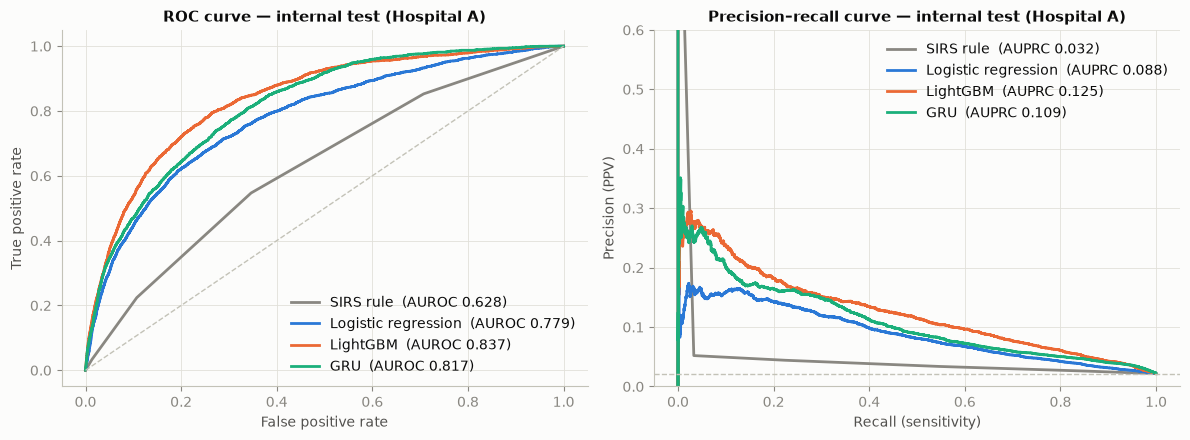

In [18]:
MODELS = list(COLORS)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for m in MODELS:
    fpr, tpr, _ = roc_curve(y["test"], preds["test"][m])
    prec, rec, _ = precision_recall_curve(y["test"], preds["test"][m])
    auroc = roc_auc_score(y["test"], preds["test"][m])
    auprc = average_precision_score(y["test"], preds["test"][m])
    axes[0].plot(fpr, tpr, color=COLORS[m], label=f"{m}  (AUROC {auroc:.3f})")
    axes[1].plot(rec, prec, color=COLORS[m], label=f"{m}  (AUPRC {auprc:.3f})")
axes[0].plot([0, 1], [0, 1], color="#c3c2b7", lw=1, ls="--")
axes[1].axhline(y["test"].mean(), color="#c3c2b7", lw=1, ls="--")
axes[0].set(title="ROC curve — internal test (Hospital A)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(title="Precision–recall curve — internal test (Hospital A)", xlabel="Recall (sensitivity)",
            ylabel="Precision (PPV)", ylim=(0, 0.6))
axes[0].legend(loc="lower right"); axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

### 11b. Patient-level alerting: what clinicians actually experience

Hour-level metrics treat a patient with 300 ICU hours as 300 independent examples. A nurse experiences something
different: **an alert fires for a patient, or it doesn't.** So we simulate a real alert system:

1. Choose **one threshold** on the *validation* set such that the model alerts on **80% of septic patients** at
   some point between ICU admission and 3 hours after clinical onset (`t_sepsis + 3`).
2. Apply that frozen threshold to the test sets and report, per patient:
   * **Sensitivity** — fraction of septic patients alerted in time.
   * **Specificity** — fraction of never-septic patients who *never* triggered an alert.
   * **PPV** — of patients who triggered an alert, the fraction who were truly septic.
     (Low PPV = alarm fatigue; nurses start ignoring alerts.)
   * **Median lead time** — hours between the first alert and clinical onset `t_sepsis` (higher = earlier warning).

In [19]:
def patient_scores(d: pd.DataFrame, p: np.ndarray) -> pd.DataFrame:
    """Max risk per patient over the eligible window + the hour of every alert-able score."""
    tmp = d[["patient_id", "ICULOS"]].assign(p=p)
    tmp["t_sepsis"] = tmp["patient_id"].map(patients["t_sepsis"])
    # For septic patients only hours up to t_sepsis + 3 count (a later alert is not "early warning").
    eligible = tmp["t_sepsis"].isna() | (tmp["ICULOS"] <= tmp["t_sepsis"] + 3)
    per = tmp[eligible].groupby("patient_id")["p"].max().to_frame("max_p")
    per["septic"] = per.index.map(patients["septic"])
    return per, tmp[eligible]


def choose_threshold(d, p, target=TARGET_SENSITIVITY):
    per, _ = patient_scores(d, p)
    # threshold = the (1 - target) quantile of septic patients' max scores -> `target` of them exceed it
    return np.quantile(per.loc[per.septic == 1, "max_p"], 1 - target)


def alert_metrics(d, p, thr):
    per, hourly = patient_scores(d, p)
    alerted = per.max_p >= thr
    sep = per.septic == 1
    # Lead time = clinical onset minus first alert hour, for septic patients who were alerted.
    first_alert = hourly[hourly.p >= thr].groupby("patient_id")["ICULOS"].min()
    first_alert = first_alert[first_alert.index.isin(per.index[sep])]
    lead = patients.loc[first_alert.index, "t_sepsis"] - first_alert
    return {
        "Sensitivity": (alerted & sep).sum() / sep.sum(),
        "Specificity": (~alerted & ~sep).sum() / (~sep).sum(),
        "PPV": (alerted & sep).sum() / max(alerted.sum(), 1),
        "Median lead time (h)": lead.median(),
        "Alerted patients (%)": alerted.mean() * 100,
    }


thresholds = {m: choose_threshold(parts["val"], preds["val"][m]) for m in MODELS}


def results_table(split):
    rows = {}
    for m in MODELS:
        rows[m] = {"AUROC": roc_auc_score(y[split], preds[split][m]),
                   "AUPRC": average_precision_score(y[split], preds[split][m]),
                   **alert_metrics(parts[split], preds[split][m], thresholds[m])}
    return pd.DataFrame(rows).T.round(3)


internal = results_table("test")
internal

,AUROC,AUPRC,Sensitivity,Specificity,PPV,Median lead time (h),Alerted patients (%)
SIRS rule,0.628,0.032,0.903,0.209,0.099,27.0,80.105
Logistic regression,0.779,0.088,0.833,0.593,0.165,29.0,44.444
LightGBM,0.837,0.125,0.822,0.668,0.193,29.0,37.529
GRU,0.817,0.109,0.770,0.687,0.192,30.0,35.333


**How to read this table.** Because each model's threshold was tuned to the *same* 80% target sensitivity on
validation, the fairest comparison is the **specificity / PPV** columns: at equal sensitivity, a better model
raises fewer false alarms. The SIRS rule has to alert on a large share of all ICU patients to reach 80%
sensitivity — that is exactly why SIRS-based screening is notorious for alarm fatigue. The learned models catch the
same share of septic patients while alerting on far fewer non-septic ones.

Be skeptical of the **lead time** column. It counts the *first* alert anywhere before onset, and septic patients
tend to look sicker from the moment they arrive, so some "29 hours of warning" alerts are really "this patient is
generally high-risk," not "sepsis is coming in the next few hours." The Challenge's utility score (Section 14)
was designed to reward alerts specifically in the 6–12 hours before onset for exactly this reason.

### 11c. Calibration: can we trust the predicted probability itself?

A model is **calibrated** if, among hours where it predicts 10% risk, about 10% are truly positive. Calibration
matters when clinicians read the number ("20% risk") rather than just the alert. (The SIRS score is not a
probability, so it is excluded.)

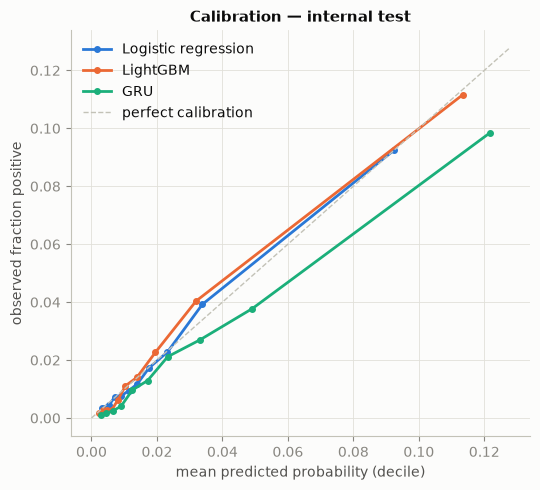

In [20]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for m in MODELS[1:]:
    frac_pos, mean_pred = calibration_curve(y["test"], preds["test"][m], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", ms=4, color=COLORS[m], label=m)
lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([0, lim], [0, lim], color="#c3c2b7", ls="--", lw=1, label="perfect calibration")
ax.set(title="Calibration — internal test", xlabel="mean predicted probability (decile)",
       ylabel="observed fraction positive")
ax.legend()
plt.tight_layout()
plt.show()

### 11d. One patient through the eyes of each model

The most intuitive way to understand an early-warning system: plot its risk score hour by hour for one patient,
together with the alert threshold and the clinical onset.

To illustrate a *successful* early warning we deliberately pick a test patient whom LightGBM flagged within the
12 hours before onset. This is a hand-picked example, not a typical one — the table above is the honest summary
(roughly 1 in 5 septic patients are missed entirely). Try changing `show_id` to other patients.

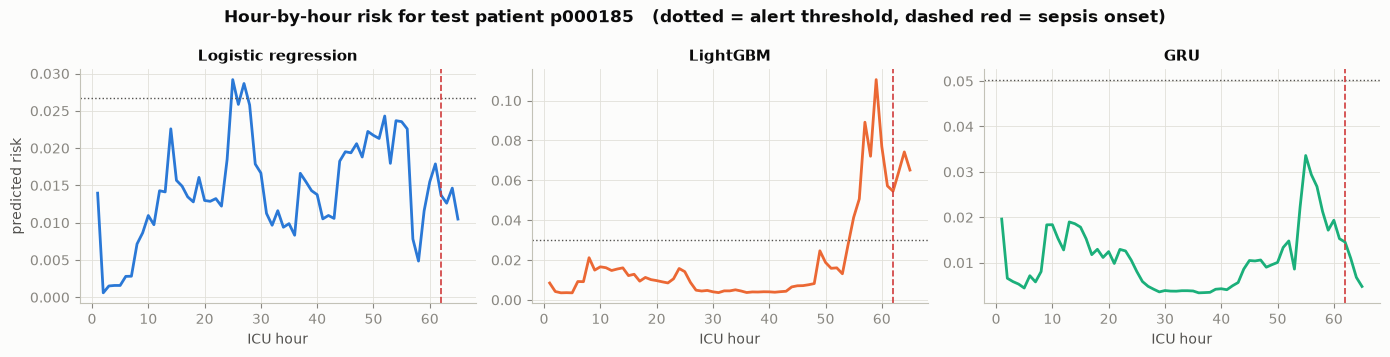

In [21]:
def first_alert_hour(pid_rows, p, thr):
    hit = np.flatnonzero(p[pid_rows] >= thr)
    return parts["test"].loc[pid_rows, "ICULOS"].iloc[hit[0]] if len(hit) else np.inf


candidates = patients.query("split == 'test' and septic == 1 and t_sepsis > 24 and 48 < n_hours < 150").index
for show_id in candidates:
    rows = (parts["test"].patient_id == show_id).to_numpy()
    lead = patients.loc[show_id, "t_sepsis"] - first_alert_hour(rows, preds["test"]["LightGBM"], thresholds["LightGBM"])
    if 0 <= lead <= 12:
        break
hours = parts["test"].loc[rows, "ICULOS"]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharex=True)
for ax, m in zip(axes, MODELS[1:]):
    ax.plot(hours, preds["test"][m][rows], color=COLORS[m])
    ax.axhline(thresholds[m], color="#52514e", ls=":", lw=1)
    ax.axvline(patients.loc[show_id, "t_sepsis"], color="#d03b3b", ls="--", lw=1.2)
    ax.set(title=m, xlabel="ICU hour")
axes[0].set_ylabel("predicted risk")
fig.suptitle(f"Hour-by-hour risk for test patient {show_id}   (dotted = alert threshold, dashed red = sepsis onset)",
             fontweight="bold")
plt.tight_layout()
plt.show()

---
## 12. Explainability with SHAP

A clinician will (rightly) ask *"why is this patient flagged?"* **SHAP** (SHapley Additive exPlanations) splits each
prediction into additive contributions from each feature, based on Shapley values from cooperative game theory:

```
model output (log-odds) = average output + SHAP(feature 1) + SHAP(feature 2) + ... + SHAP(feature n)
```

For tree models `shap.TreeExplainer` computes these exactly and quickly. We explain a random sample of 5,000
internal-test hours.

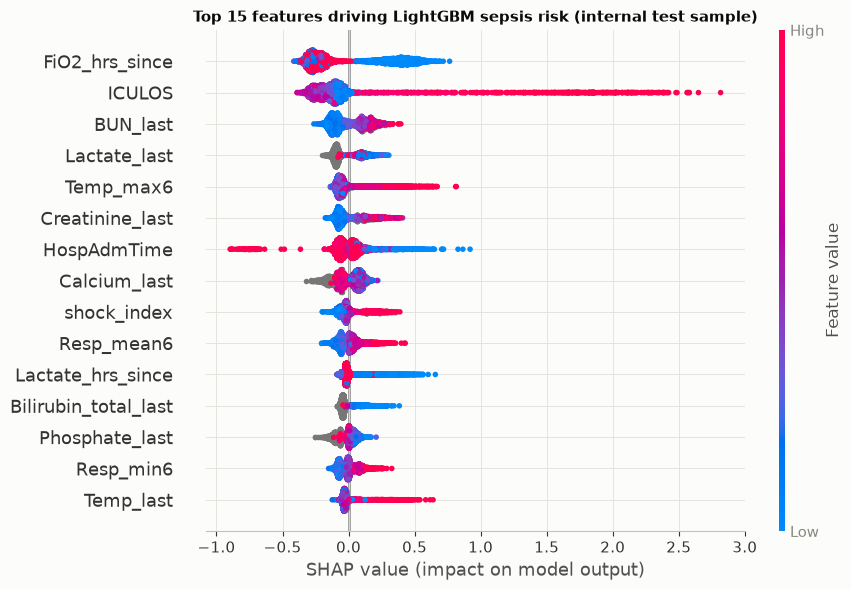

In [22]:
sample = X["test"].sample(5000, random_state=SEED)
explainer = shap.TreeExplainer(gbm)
shap_values = explainer.shap_values(sample)
if isinstance(shap_values, list):              # older SHAP versions return [class0, class1]
    shap_values = shap_values[1]

pretty = sample.rename(columns=lambda c: c[2:])  # drop the 'f_' prefix for readable plots
shap.summary_plot(shap_values, pretty, max_display=15, show=False, plot_size=(9, 6))
plt.title("Top 15 features driving LightGBM sepsis risk (internal test sample)")
plt.tight_layout()
plt.show()

**How to read the beeswarm.** Each dot is one patient-hour. Its horizontal position is how much that feature pushed
the prediction up (right) or down (left); its color is the feature's value (red = high, blue = low).

Grey dots are hours where the feature was missing (never measured); LightGBM learned where to send those.

What our model learned (your exact ranking may differ slightly):
* **`FiO2_hrs_since` is the #1 feature.** FiO2 (fraction of inspired oxygen) is only charted for patients on
  supplemental oxygen or a ventilator, so "FiO2 was charted recently" (blue = few hours ago → pushes risk up) is a
  proxy for *being on respiratory support*. `Lactate_hrs_since` behaves the same way: a lactate gets drawn when
  someone is worried. The model is partly learning **clinician behavior**, not just physiology.
* **`ICULOS` and `HospAdmTime`** — time in the ICU and time from hospital admission. Long stays push risk up
  strongly. Part of this is real (longer exposure to lines, ventilators and hospital infections), part is the
  dataset's structure (septic patients have longer records). A dominant time feature is a prompt to ask whether the
  model learns *physiology* or *the shape of the dataset*.
* **Physiology**: high `BUN`, `Lactate`, `Creatinine` (organ dysfunction — the "O" in the Sepsis-3 definition),
  high `Temp_max6`, high `shock_index` and fast `Resp_mean6` — the signals we would expect a clinician to use.

### Explaining a single alert
Now the explanation a clinician would see for the patient plotted in Section 11d, at the hour of the first alert.

Explaining patient p000185 at ICU hour 55, predicted risk 0.04


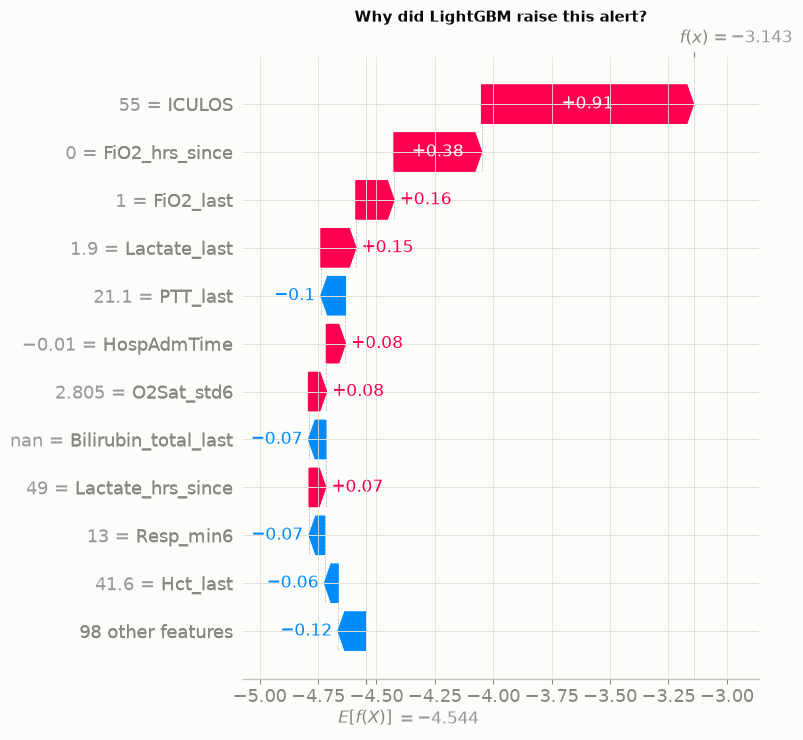

In [23]:
show_rows = parts["test"].index[rows]
show_p = preds["test"]["LightGBM"][rows]
alert_pos = np.flatnonzero(show_p >= thresholds["LightGBM"])
i = show_rows[alert_pos[0]] if len(alert_pos) else show_rows[np.argmax(show_p)]
print(f"Explaining patient {show_id} at ICU hour {int(parts['test'].loc[i, 'ICULOS'])}, "
      f"predicted risk {preds['test']['LightGBM'][i]:.2f}")

single = explainer(X["test"].loc[[i]].rename(columns=lambda c: c[2:]))
shap.plots.waterfall(single[0], max_display=12, show=False)
plt.title("Why did LightGBM raise this alert?")
plt.tight_layout()
plt.show()

---
## 13. External validation at Hospital B

Everything so far used Hospital A. Hospital B has different patients, different charting practices and different
lab ordering habits. **The models are applied unchanged — same weights, same thresholds.** This mimics buying a
sepsis model developed elsewhere and installing it in your hospital.

In [24]:
external = results_table("ext")
comparison = pd.concat({"Internal test (Hospital A)": internal[["AUROC", "AUPRC", "Sensitivity", "Specificity", "PPV"]],
                        "External (Hospital B)": external[["AUROC", "AUPRC", "Sensitivity", "Specificity", "PPV"]]},
                       axis=1)
comparison

Internal test (Hospital A)                                       External (Hospital B)                                      
                                         AUROC  AUPRC Sensitivity Specificity    PPV                 AUROC  AUPRC Sensitivity Specificity    PPV
SIRS rule                                0.628  0.032       0.903       0.209  0.099                 0.665  0.028       0.868       0.330  0.073
Logistic regression                      0.779  0.088       0.833       0.593  0.165                 0.706  0.053       0.594       0.721  0.114
LightGBM                                 0.837  0.125       0.822       0.668  0.193                 0.783  0.070       0.658       0.783  0.155
GRU                                      0.817  0.109       0.770       0.687  0.192                 0.774  0.062       0.605       0.823  0.171

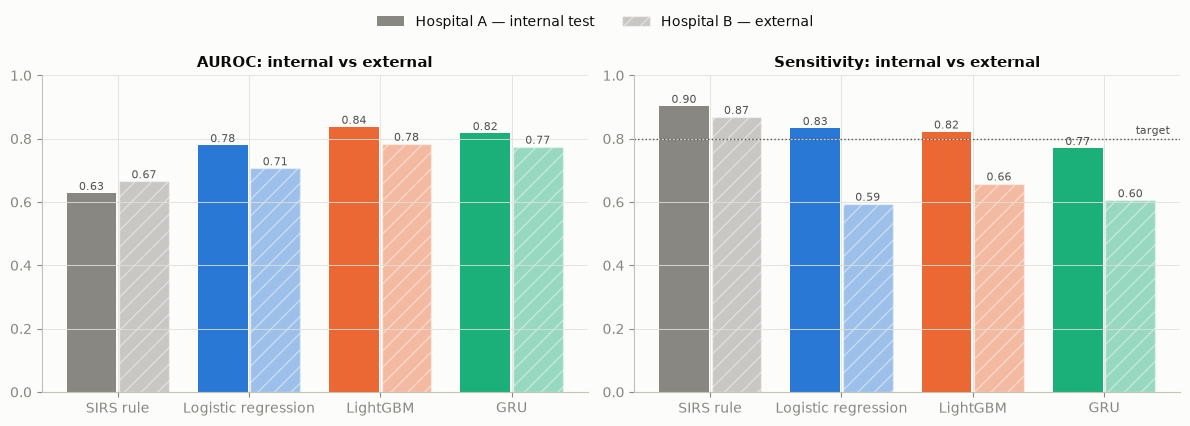

In [25]:
from matplotlib.patches import Patch

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
xpos = np.arange(len(MODELS))
for ax, metric in zip(axes, ["AUROC", "Sensitivity"]):
    # solid bar = Hospital A (internal test), lighter hatched bar = Hospital B (external)
    ax.bar(xpos - 0.2, internal[metric], width=0.38, color=[COLORS[m] for m in MODELS])
    ax.bar(xpos + 0.2, external[metric], width=0.38, color=[COLORS[m] for m in MODELS], alpha=0.45,
           hatch="//", edgecolor="#fcfcfb")
    for xi, (a, b) in enumerate(zip(internal[metric], external[metric])):
        ax.text(xi - 0.2, a + 0.01, f"{a:.2f}", ha="center", fontsize=8, color="#52514e")
        ax.text(xi + 0.2, b + 0.01, f"{b:.2f}", ha="center", fontsize=8, color="#52514e")
    ax.set_xticks(xpos, MODELS)
    ax.set(title=f"{metric}: internal vs external", ylim=(0, 1.0))
axes[1].axhline(TARGET_SENSITIVITY, color="#52514e", ls=":", lw=1)
axes[1].text(len(MODELS) - 0.5, TARGET_SENSITIVITY + 0.015, "target", ha="right", fontsize=8, color="#52514e")
fig.legend(handles=[Patch(facecolor="#898781", label="Hospital A — internal test"),
                    Patch(facecolor="#898781", alpha=0.45, hatch="//", edgecolor="#fcfcfb",
                          label="Hospital B — external")],
           loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02))
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

**What happened here:** every learned model loses discrimination at Hospital B (AUROC drops by ~0.04–0.07), and —
more importantly for deployment — the **frozen threshold no longer delivers the 80% sensitivity it was tuned for**:
the learned models now catch only about 60–66% of septic patients. A different case mix and different measurement
habits shift the whole score distribution. The SIRS rule, by contrast, barely moves: it has no parameters fitted to
Hospital A, so there is nothing to overfit — but it is still far worse than every learned model.

The same pattern played out in real life with
the widely deployed *Epic Sepsis Model*, whose external validation (Wong et al., *JAMA Internal Medicine* 2021)
found far worse performance than the vendor reported. Lessons:

1. Always validate externally before deployment.
2. Expect to **recalibrate / re-pick the threshold locally** (a "silent" trial period in the new hospital).
3. Features that encode *local clinician behavior* (`hrs_since`) are the least likely to transport.

---
## 14. Takeaways, limitations and exercises

### Key takeaways
* **Split by patient** (and ideally by hospital/time). Row-level splits leak.
* **Causal features only** — and test for it (Section 6's truncation test).
* In rare-event problems, report **AUPRC and patient-level alert metrics**, not accuracy.
* Choose the alert threshold on validation data to meet a **clinical target** (e.g. 80% sensitivity), then report
  the resulting **false-alarm burden (specificity, PPV)**.
* Gradient boosting is a very strong default for tabular EHR data; a GRU learns from raw sequences with less
  feature engineering. Compare honestly — the "deep" model is not automatically better.
* Explanations (SHAP) can reveal **what** the model learned — including shortcuts like clinician behavior and length
  of stay — which is as important as the score.

### Limitations
* The **Sepsis-3 label is computed retrospectively** from the same EHR data (including antibiotic and culture orders).
  Models can partially learn the *labeling process* rather than the disease.
* **Patients septic on arrival** are included; they inflate sensitivity without offering any true early warning.
* The 2019 Challenge used a custom **utility score** that rewards alerts 6–12 h before onset and penalizes late or
  false alerts. We used more standard metrics; implementing the utility score is a great extension.
* Hourly rows from the same patient are correlated, so hour-level metrics overstate the effective sample size.
  Bootstrap **confidence intervals by resampling patients** would quantify uncertainty.

### Exercises for the reader
1. **Ablation:** drop all `*_hrs_since` features and retrain LightGBM. How much performance came from measurement
   *patterns* rather than measurement *values*? Does external performance get better or worse?
2. **Recalibrate for Hospital B:** pick a new threshold using 20% of Hospital B patients and re-evaluate on the rest.
3. **Train on both hospitals** (with a hospital-level split) and compare to the single-site model.
4. **Swap the GRU for an LSTM or a small causal Transformer** (with a causal attention mask!).
5. **Fairness:** compute sensitivity and PPV separately by sex and age group (<65 vs ≥65). Are alerts equitable?
6. **Bootstrap** 95% confidence intervals for AUROC/AUPRC by resampling patients.

### References
* Reyna MA, *et al.* Early Prediction of Sepsis From Clinical Data: The PhysioNet/Computing in Cardiology Challenge
  2019. *Critical Care Medicine* 2020;48(2):210–217.
* Goldberger AL, *et al.* PhysioBank, PhysioToolkit, and PhysioNet. *Circulation* 2000;101(23):e215–e220.
* Singer M, *et al.* The Third International Consensus Definitions for Sepsis and Septic Shock (Sepsis-3).
  *JAMA* 2016;315(8):801–810.
* Wong A, *et al.* External Validation of a Widely Implemented Proprietary Sepsis Prediction Model in Hospitalized
  Patients. *JAMA Internal Medicine* 2021;181(8):1065–1070.
* Lundberg SM, Lee S-I. A Unified Approach to Interpreting Model Predictions (SHAP). *NeurIPS* 2017.
* Ke G, *et al.* LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS* 2017.
* Cho K, *et al.* Learning Phrase Representations using RNN Encoder–Decoder (GRU). *EMNLP* 2014.